# What attention needs to remember

An executable investigation of attention backward, saved activation storage and recomputation.

**Scope:** an educational implementation of established mathematics, prepared with coding assistance. No claim of a new attention algorithm or GPU performance. Float32/64, square self-attention, optional causal masking, no dropout or higher-order gradients.

The question: does backward need the probability matrix **stored**, or does it only need a way to **evaluate** it?

In [1]:
from pathlib import Path
import inspect
import json
import torch
from IPython.display import display, Markdown, Image
from attention import reference, chunked, recompute, pytorch_math, _RecomputeAttention
from benchmark import saved_storage
ROOT = Path.cwd()
torch.set_num_threads(1)
torch.manual_seed(20261027)
print(f"PyTorch {torch.__version__}; CPU; one thread")

PyTorch 2.13.0; CPU; one thread


## 1. Forward operation

For one head, $Q,K\in\mathbb R^{N\times d}$ and $V\in\mathbb R^{N\times d_v}$:

$$S=QK^T/\sqrt d+M,\qquad P=\operatorname{softmax}_{row}(S),\qquad O=PV.$$

The causal mask is zero for $j\le i$ and $-\infty$ otherwise. There is at least one allowed entry per row. Q/K/V input storage is kept separate from additional intermediate storage in the measurements below.

## 2. Derive the softmax backward

Let $G=\partial\mathcal L/\partial O$. From $O=PV$,

$$\bar V=P^TG,\qquad\bar P=GV^T.$$

For one row, $\partial p_j/\partial s_k=p_j(\delta_{jk}-p_k)$. Applying the chain rule gives

$$\bar s_k=\sum_j\bar p_jp_j(\delta_{jk}-p_k)=p_k\left(\bar p_k-\sum_jp_j\bar p_j\right).$$

Consequently $\sum_k\bar s_k=0$: a uniform shift of all logits leaves softmax unchanged. Test both the analytic derivative and this invariant.

In [2]:
s = torch.randn(2, 5, dtype=torch.float64, requires_grad=True)
h = torch.randn_like(s)
p = s.softmax(-1)
analytic = p * (h - (p * h).sum(-1, keepdim=True))
automatic = torch.autograd.grad(p, s, h)[0]
torch.testing.assert_close(analytic, automatic, atol=1e-12, rtol=1e-10)
torch.testing.assert_close(analytic.sum(-1), torch.zeros(2, dtype=s.dtype), atol=1e-12, rtol=0)
print(f"Maximum derivative error: {(analytic-automatic).abs().max().item():.2e}")
print(f"Maximum absolute row sum: {analytic.sum(-1).abs().max().item():.2e}")

Maximum derivative error: 0.00e+00
Maximum absolute row sum: 1.67e-16


## 3. Complete the chain rule

$$\bar S=P\odot[\bar P-\operatorname{rowsum}(P\odot\bar P)],$$
$$\bar Q=\bar S K/\sqrt d,\qquad\bar K=\bar S^TQ/\sqrt d.$$

The row sum is a column vector broadcast across keys. Masked probabilities are zero, so masked score gradients are zero.

Across query blocks, Q gradients occupy disjoint slices, but K and V gradients **accumulate**. Overwriting them with the last block would be incorrect.

## 4. Reconstruct probabilities

For row $i$, save $L_i=\log\sum_j\exp(S_{ij})$, evaluated stably:

$$m_i=\max_j S_{ij},\qquad L_i=m_i+\log\sum_j\exp(S_{ij}-m_i).$$

Then reconstruct $P_{ij}=\exp(S_{ij}-L_i)$ from Q, K and one saved scalar per row. This identity is exact over real numbers, not necessarily bitwise exact in floating point. Because this baseline still visits all keys for each query block, L could instead be recomputed; retaining it avoids that reduction.

The implementation below uses an explicit first-order backward, not a graph of ordinary autograd operations saved during forward.

In [3]:
display(Markdown("```python\n" + inspect.getsource(_RecomputeAttention) + "\n```"))

```python
class _RecomputeAttention(torch.autograd.Function):
    @staticmethod
    def forward(ctx, q, k, v, causal, chunk_size):
        n, dim = q.shape[-2:]
        outputs, normalizers = [], []
        for start in range(0, n, chunk_size):
            stop = min(start + chunk_size, n)
            scores = (q[..., start:stop, :] @ k.transpose(-2, -1)) / math.sqrt(dim)
            if causal:
                allowed = torch.arange(n, device=q.device)[None, :] <= torch.arange(start, stop, device=q.device)[:, None]
                scores = scores.masked_fill(~allowed, -torch.inf)
            lse = torch.logsumexp(scores, dim=-1, keepdim=True)
            probabilities = torch.exp(scores - lse)
            outputs.append(probabilities @ v)
            normalizers.append(lse)
        ctx.save_for_backward(q, k, v, torch.cat(normalizers, dim=-2))
        ctx.causal, ctx.chunk_size = causal, chunk_size
        return torch.cat(outputs, dim=-2)

    @staticmethod
    @once_differentiable
    def backward(ctx, upstream):
        # Analytic first-order backward. No nested autograd graph or N×N cache.
        q, k, v, lse = ctx.saved_tensors
        n, dim = q.shape[-2:]
        scale = 1 / math.sqrt(dim)
        dq, dk, dv = torch.zeros_like(q), torch.zeros_like(k), torch.zeros_like(v)
        for start in range(0, n, ctx.chunk_size):
            stop = min(start + ctx.chunk_size, n)
            qi, gi = q[..., start:stop, :], upstream[..., start:stop, :]
            scores = (qi @ k.transpose(-2, -1)) * scale
            if ctx.causal:
                allowed = torch.arange(n, device=q.device)[None, :] <= torch.arange(start, stop, device=q.device)[:, None]
                scores = scores.masked_fill(~allowed, -torch.inf)
            p = torch.exp(scores - lse[..., start:stop, :])
            dp = gi @ v.transpose(-2, -1)
            ds = p * (dp - (p * dp).sum(dim=-1, keepdim=True))
            dq[..., start:stop, :] = (ds @ k) * scale
            dk.add_((ds.transpose(-2, -1) @ qi) * scale)
            dv.add_(p.transpose(-2, -1) @ gi)
        return dq, dk, dv, None, None

```

## 5. Validate the implementation

Compare output and gradients with the explicitly selected PyTorch math backend, using a fixed random upstream gradient rather than only summing the output. Also run independent finite-difference checks, causal invariance, strided inputs and large finite logits.

Float64 tolerances: atol $10^{-10}$, rtol $10^{-9}$. Float32: atol $2\times10^{-5}$, rtol $2\times10^{-4}$. The large-logit float64 stress cases use atol $10^{-9}$ and rtol $10^{-8}$. These are declared before execution.

In [4]:
import check
check.main()
report = json.loads((ROOT / "results/correctness.json").read_text())
assert len(report["comparison_cases"]) == 96
assert all(case["status"] == "passed" for case in report["stability_and_chunk_sizes"])
print("All six additional chunk-size / large-logit cases passed.")

PASS: 96 output/gradient comparisons; causal invariance; finite-difference gradients; invalid shapes
Worst absolute output error: 1.6689300537109375e-06
Worst absolute gradient error: 1.6689300537109375e-06
All six additional chunk-size / large-logit cases passed.


## 6. Predict storage, then measure it

One full probability matrix costs $bN^2$ bytes per head. Chunking queries into C rows reduces each block to $bCN$, but retaining $N/C$ blocks still costs $bN^2$.

The recomputing implementation saves $bN$ additional bytes per head for L. Including input tensors, its context costs $b[N(2d+d_v)+N]$ per head. This is **not** peak memory: outputs, upstream gradients, gradient buffers, temporary tensors and the allocator also consume memory.

Saved-tensor hooks below deduplicate underlying storages and exclude pre-existing input storage. No GPU measurements are made.

In [5]:
rows = []
for n in (128, 512, 1024):
    inputs = [torch.randn(1, 8, n, 64, requires_grad=True) for _ in range(3)]
    upstream = torch.randn_like(inputs[0])
    values = [saved_storage(fn, inputs, upstream, False) for fn in (reference, chunked, recompute)]
    assert values[0] == values[1] == 8*n*n*4
    assert values[2] == 8*n*4
    rows.append(f"| {n} | {values[0]/2**20:g} MiB | {values[1]/2**20:g} MiB | {values[2]/2**10:g} KiB |")
display(Markdown("| Tokens | Direct | Query chunks | Recomputed backward |\n|---:|---:|---:|---:|\n" + "\n".join(rows)))

| Tokens | Direct | Query chunks | Recomputed backward |
|---:|---:|---:|---:|
| 128 | 0.5 MiB | 0.5 MiB | 4 KiB |
| 512 | 8 MiB | 8 MiB | 16 KiB |
| 1024 | 32 MiB | 32 MiB | 32 KiB |

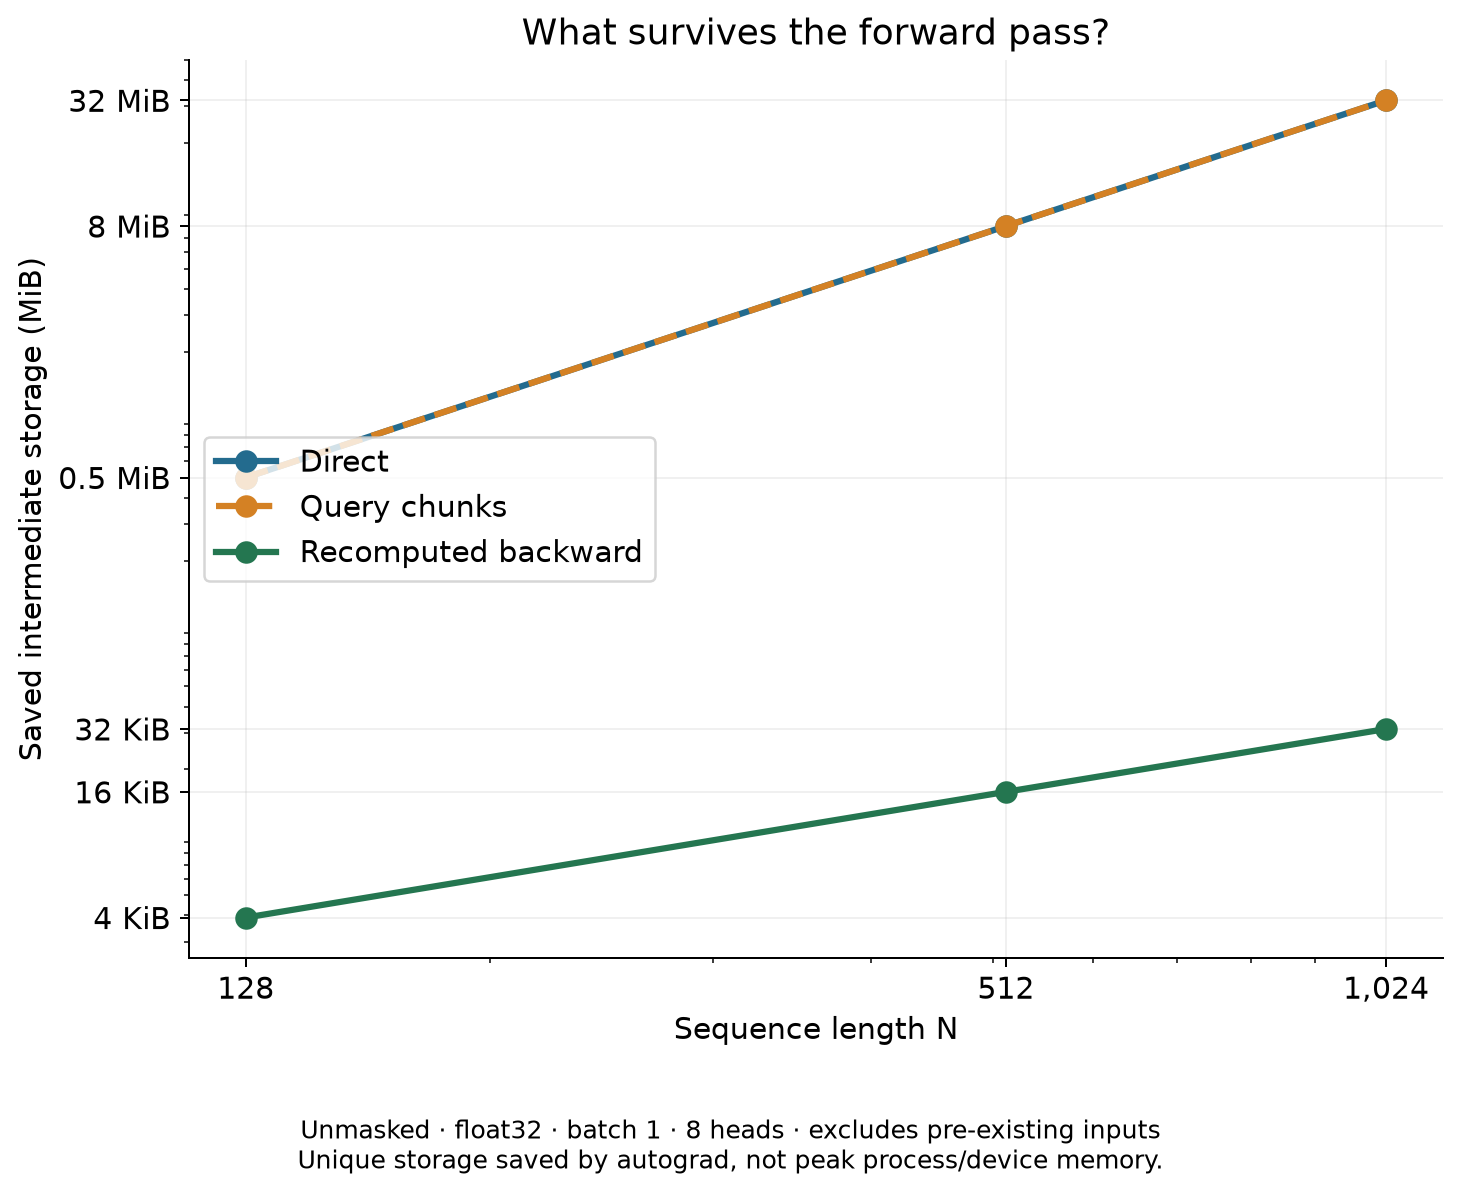

In [6]:
display(Image(filename=str(ROOT / "results/storage.png")))

## 7. What does it cost?

Recomputing adds a QK product and normalization reconstruction in backward, as well as Python-loop overhead. Dense arithmetic remains quadratic. We do not implement key-axis tiling, custom GPU kernels or the complete FlashAttention algorithm.

The following figure uses recorded local CPU measurements, **not timings executed by this notebook cell**. The JSON includes raw samples and source hashes. Re-run `python benchmark.py --repeats 20` followed by `python plot.py` to generate a new measurement set. Other active processes can affect timings.

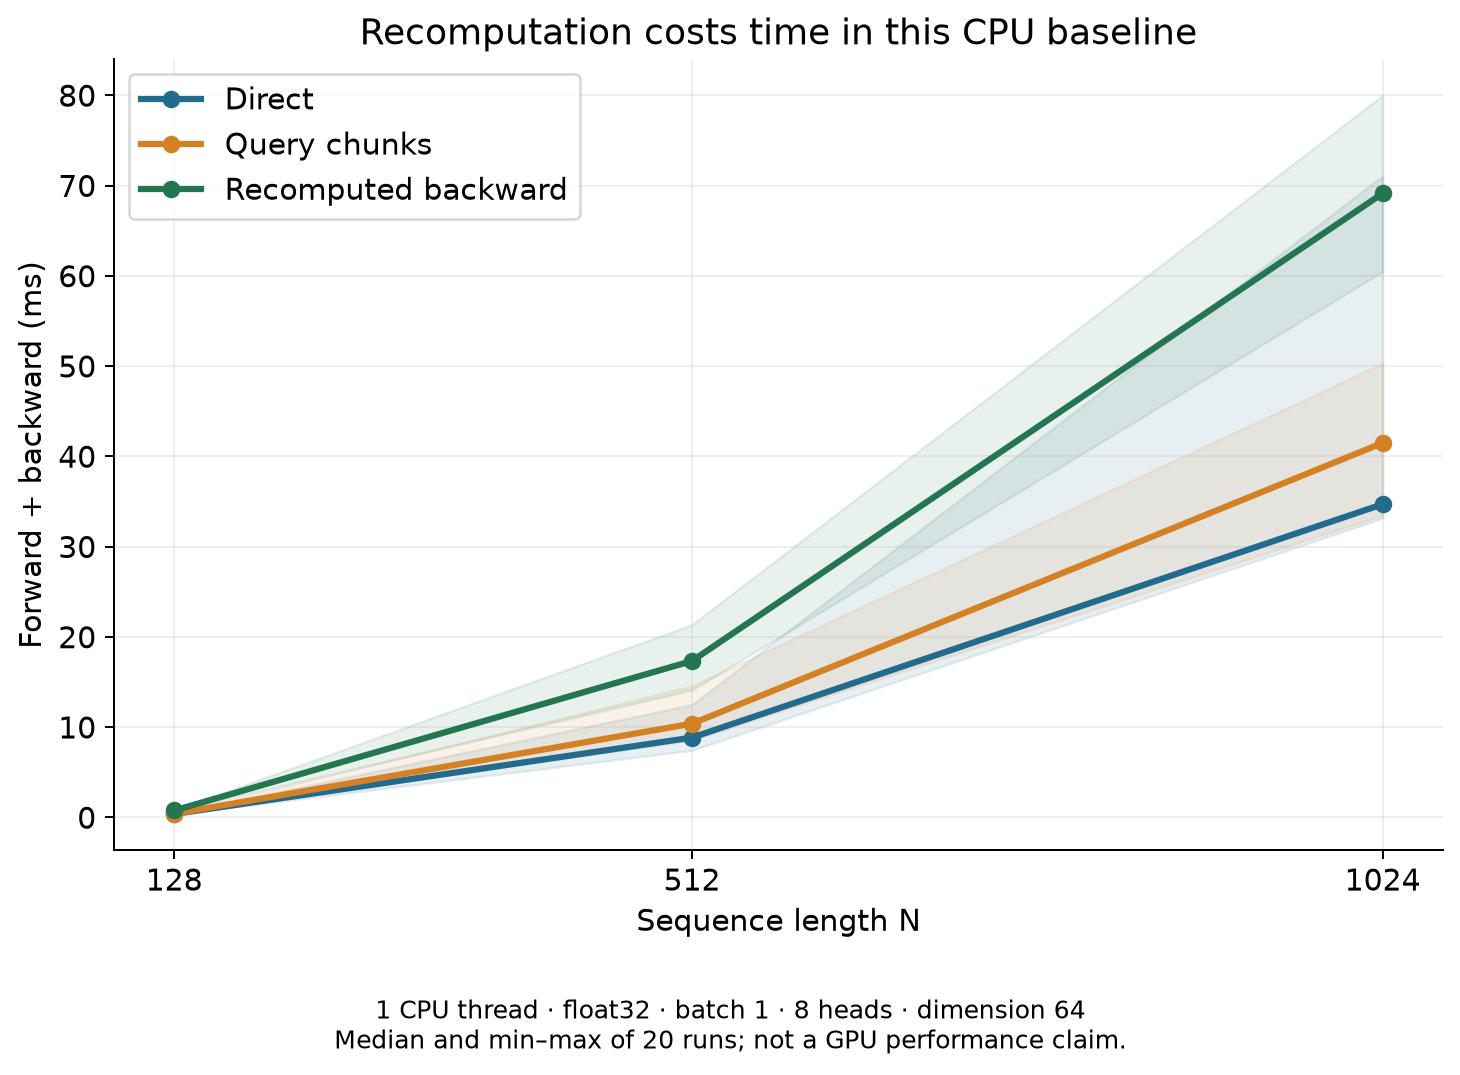

In [7]:
measurements = json.loads((ROOT / "results/benchmark.json").read_text())
assert measurements["environment"]["device"] == "cpu"
display(Image(filename=str(ROOT / "results/latency.png")))

## Conclusion and limitations

Backward needs attention probabilities, but not necessarily a retained probability matrix. Reconstructing it from inputs and per-row normalization removes the saved quadratic intermediate in this baseline.

This verifies **retained storage**, not end-to-end peak allocation or faster training. The custom implementation supports first-order derivatives only, has no dropout or padding-mask handling, and is validated for float32/64. CPU timings cannot establish GPU performance.

Original algorithm context: [FlashAttention](https://arxiv.org/abs/2205.14135). API reference: [PyTorch scaled dot-product attention](https://docs.pytorch.org/docs/2.13/generated/torch.nn.functional.scaled_dot_product_attention.html).

The work here is an explanatory derivation and implementation of established ideas. It should not be presented as a new research contribution.